# Featurization pipeline overview figure (2 × 2)

Builds the schematic from the hand sketch entirely from matplotlib polygons/patches (no external images), laid out as a wide 2 × 2 grid:

| | |
|---|---|
| **i. Volumetric acquisition:** fine vs. coarse z-step (Δz) | **iii. Handcrafted featurization:** 3D volume or 2D image → caliper + compass (engineered measurements) → **f**<sub>hc</sub> |
| **ii. 3D → 2D sampling:** max over all z, max of *k* central slices, middle z-slice | **iv. Deep learning featurization (ViT):** unmasked or masked input (DL only) → patch tokens + [CLS] → Transformer encoder → **f**<sub>dl</sub> |

Colors and text sizes are set in the first code cell. The column widths and row heights are set at the top of `make_figure`. Running the last cell saves PNG (300 dpi), PDF and SVG versions.

## 1 · Style, palette and text sizes

In [1]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import (
    Circle,
    Ellipse,
    FancyArrowPatch,
    FancyBboxPatch,
    Polygon,
    Rectangle,
)
from notebook_init_utils.notebook_init_utils import init_notebook

root_dir, in_notebook = init_notebook()

output_figure_file_path = pathlib.Path(
    f"{root_dir}/figures/assembled_figure_2/figures/featurization_figure.png"
)
output_figure_file_path.parent.mkdir(parents=True, exist_ok=True)

In [2]:
# ---------------- Style / palette (edit here) ----------------
INK = "#1f2430"  # outlines + text
MUTED = "#5b6170"  # secondary text
SPHERE = "#7aa6c2"  # 3D volume base color
SLICE = "#e07a3f"  # z-slice planes
FUNNEL = "#e07a3f"  # 3D->2D sampling wedge
HAND = "#c9a227"  # handcrafted features accent
DEEP = "#6a4c93"  # deep learning (ViT) accent
MASKC = "#2a9d8f"  # masking accent
FLUO = LinearSegmentedColormap.from_list(
    "fluo", ["#05070c", "#0f3b46", "#2fa3a0", "#bff5e6", "#ffffff"]
)

# ---------------- Text sizes (pt) ----------------
FS_PANEL = 22  # panel numeral (i, ii, ...)
FS_TITLE = 18  # panel title
FS_LABEL = 15  # main labels
FS_SMALL = 13.5  # secondary labels
FS_SYM = 20  # operator symbols (⊙, =, or)

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": FS_LABEL,
        "text.color": INK,
        "mathtext.fontset": "dejavusans",
    }
)
RNG = np.random.default_rng(7)

## 2 · Drawing primitives
Shaded sphere (the volume), oblique z-slice planes, synthetic micrograph tiles (with optional ViT patch grid), arrows, brackets and dividers.

In [3]:
def shade(color, f):
    """f<1 darkens, f>1 lightens toward white."""
    c = np.array(to_rgb(color))
    return tuple(np.clip(c * f, 0, 1)) if f <= 1 else tuple(c + (1 - c) * (f - 1))


def draw_sphere(ax, c, r, color=SPHERE, z=2):
    """Lambert-shaded sphere (the 3D volume), drawn as a clipped image inside a circle polygon."""
    n = 300
    y, x = np.mgrid[1 : -1 : n * 1j, -1 : 1 : n * 1j]
    rr = x**2 + y**2
    nz = np.sqrt(np.clip(1 - rr, 0, 1))
    L = np.array([-0.45, 0.55, 0.70])
    L /= np.linalg.norm(L)
    I = np.clip(x * L[0] + y * L[1] + nz * L[2], 0, 1) * 0.75 + 0.25
    base = np.array(to_rgb(color))
    rgb = np.clip(base[None, None] * I[..., None] * 1.15, 0, 1)
    rgb = rgb + (1 - rgb) * (I[..., None] ** 12) * 0.6  # specular highlight
    rgba = np.dstack([rgb, (rr <= 1).astype(float)])
    outline = Circle(c, r, fc="none", ec=INK, lw=1.5, zorder=z + 0.5)
    ax.add_patch(outline)
    im = ax.imshow(
        rgba,
        extent=[c[0] - r, c[0] + r, c[1] - r, c[1] + r],
        zorder=z,
        interpolation="bilinear",
    )
    im.set_clip_path(outline)
    return outline


def draw_slice(
    ax,
    c,
    r,
    dz,
    color=SLICE,
    w_scale=1.45,
    depth=0.30,
    skew=0.22,
    z=4,
    alpha=0.22,
    lw=1.1,
):
    """A horizontal imaging plane at height dz cutting a sphere (oblique view): parallelogram + elliptical cross-section."""
    cx, cy = c[0], c[1] + dz
    w, h, s = w_scale * r, depth * r, skew * r
    quad = [
        (cx - w + s, cy + h),
        (cx + w + s, cy + h),
        (cx + w - s, cy - h),
        (cx - w - s, cy - h),
    ]
    ax.add_patch(Polygon(quad, closed=True, fc=color, ec="none", alpha=alpha, zorder=z))
    ax.add_patch(
        Polygon(
            quad, closed=True, fc="none", ec=shade(color, 0.7), lw=lw, zorder=z + 0.1
        )
    )
    rho = np.sqrt(max(r**2 - dz**2, 0))
    if rho > 0:
        ax.add_patch(
            Ellipse(
                (cx, cy),
                2 * rho,
                2 * rho * h / w * 1.6,
                fc=shade(color, 1.2),
                ec="none",
                alpha=0.35,
                zorder=z + 0.2,
            )
        )
        ax.add_patch(
            Ellipse(
                (cx, cy),
                2 * rho,
                2 * rho * h / w * 1.6,
                fc="none",
                ec=shade(color, 0.55),
                lw=1.1,
                zorder=z + 0.25,
            )
        )
    return rho


def fake_micrograph(
    n=160, blob_r=0.42, center=(0, 0), neighbors=True, brightness=1.0, seed=0
):
    """Synthetic fluorescence image: one cell of interest + optional neighboring cells + noise. Returns (image, mask)."""
    rng = np.random.default_rng(seed)
    y, x = np.mgrid[1 : -1 : n * 1j, -1 : 1 : n * 1j]

    def blob(x0, y0, r, a):
        d = np.sqrt((x - x0) ** 2 + (y - y0) ** 2) / r
        return a / (1 + np.exp((d - 1) * 9)) * (0.75 + 0.25 * np.cos(6 * x + 4 * y))

    img = blob(*center, blob_r, brightness)
    if neighbors:
        for x0, y0, r, a in [
            (-0.85, 0.75, 0.30, 0.55),
            (0.9, -0.7, 0.35, 0.5),
            (0.85, 0.85, 0.2, 0.4),
            (-0.8, -0.85, 0.25, 0.35),
        ]:
            img += blob(x0, y0, r, a)
        img += 0.06 * rng.random((n, n))
    mask = (
        np.sqrt((x - center[0]) ** 2 + (y - center[1]) ** 2) <= blob_r * 1.08
    ).astype(float)
    return np.clip(img, 0, 1), mask


def draw_tile(
    ax, c, size, img, cmap=FLUO, persp=0.10, z=3, lw=1.5, grid=0, grid_color="white"
):
    """A 2D image as a slightly-perspective quad (as in the sketch), image clipped inside. grid>0 overlays ViT patches."""
    x, y = c
    hs = size / 2
    quad = [
        (x - hs, y + hs * (1 - persp)),
        (x + hs, y + hs),
        (x + hs, y - hs),
        (x - hs, y - hs * (1 - persp)),
    ]
    ax.add_patch(
        Polygon(
            [(px + 0.07, py - 0.07) for px, py in quad],
            fc="black",
            alpha=0.15,
            ec="none",
            zorder=z - 0.2,
        )
    )
    frame = Polygon(quad, closed=True, fc="none", ec=INK, lw=lw, zorder=z + 0.5)
    ax.add_patch(frame)
    im = ax.imshow(
        img,
        extent=[x - hs, x + hs, y - hs, y + hs],
        cmap=cmap,
        vmin=0,
        vmax=1,
        zorder=z,
        interpolation="bilinear",
    )
    im.set_clip_path(frame)
    for k in range(1, grid):
        t = -hs + 2 * hs * k / grid
        top_y = y + hs * (
            1 - persp * (1 - (t + hs) / (2 * hs))
        )  # follow the perspective top/bottom edges
        (ln1,) = ax.plot(
            [x + t, x + t],
            [2 * y - top_y, top_y],
            color=grid_color,
            lw=1.0,
            alpha=0.85,
            zorder=z + 0.3,
        )
        (ln2,) = ax.plot(
            [x - hs, x + hs],
            [y + t, y + t],
            color=grid_color,
            lw=1.0,
            alpha=0.85,
            zorder=z + 0.3,
        )
        ln1.set_clip_path(frame)
        ln2.set_clip_path(frame)
    return quad


def arrow(ax, p0, p1, color=INK, lw=1.8, ms=18, rad=0.0, z=5):
    ax.add_patch(
        FancyArrowPatch(
            p0,
            p1,
            arrowstyle="-|>",
            mutation_scale=ms,
            lw=lw,
            color=color,
            connectionstyle=f"arc3,rad={rad}",
            zorder=z,
            shrinkA=0,
            shrinkB=0,
        )
    )


def bracket(ax, x, y0, y1, text, color=INK, tick=0.15, fs=FS_LABEL):
    ax.plot([x, x + tick, x + tick, x], [y0, y0, y1, y1], color=color, lw=1.3, zorder=6)
    ax.text(
        x + tick + 0.12,
        (y0 + y1) / 2,
        text,
        ha="left",
        va="center",
        fontsize=fs,
        color=color,
    )


def panel_label(ax, x, y, numeral, title):
    ax.text(
        x,
        y,
        numeral,
        fontsize=FS_PANEL,
        fontweight="bold",
        fontstyle="italic",
        va="center",
    )
    ax.text(
        x + 0.32 + 0.28 * len(numeral),
        y,
        title,
        fontsize=FS_TITLE,
        va="center",
        fontweight="bold",
    )


def separator(fig, x0, y0, x1, y1):
    """Light divider line in figure-fraction coordinates."""
    fig.add_artist(
        plt.Line2D(
            [x0, x1], [y0, y1], color="#d5d7dc", lw=1.2, transform=fig.transFigure
        )
    )

## 3 · Method glyphs
Vernier caliper (measuring a cell) and drawing compass for handcrafted features; Vision Transformer (patch tokens, [CLS], positional embeddings, self-attention encoder × L); output feature vector.

In [4]:
def draw_caliper(ax, c, z=6, color=HAND):
    """Handcrafted-feature glyph: a vernier caliper measuring a cell (engineered, human-defined measurement)."""
    x, y = c
    edge = dict(ec=INK, lw=1.3)
    # beam with tick marks
    ax.add_patch(
        Rectangle(
            (x - 1.25, y + 0.35), 2.6, 0.28, fc=shade(color, 1.5), zorder=z, **edge
        )
    )
    for i, xx in enumerate(np.linspace(x - 1.0, x + 1.25, 24)):
        tl = 0.17 if i % 5 == 0 else 0.09
        ax.plot([xx, xx], [y + 0.63, y + 0.63 - tl], color=INK, lw=0.8, zorder=z + 0.1)
    # fixed jaw (left): lower measuring jaw + small upper jaw
    ax.add_patch(
        Polygon(
            [
                (x - 1.25, y + 0.35),
                (x - 0.95, y + 0.35),
                (x - 0.95, y - 0.55),
                (x - 1.05, y - 0.75),
                (x - 1.25, y - 0.55),
            ],
            fc=shade(color, 1.15),
            zorder=z + 0.2,
            **edge,
        )
    )
    ax.add_patch(
        Polygon(
            [
                (x - 1.25, y + 0.63),
                (x - 1.05, y + 0.63),
                (x - 1.05, y + 0.88),
                (x - 1.15, y + 0.95),
                (x - 1.25, y + 0.88),
            ],
            fc=shade(color, 1.15),
            zorder=z + 0.2,
            **edge,
        )
    )
    # sliding jaw (right) with its head around the beam
    jx = x + 0.05
    ax.add_patch(
        Polygon(
            [
                (jx, y + 0.35),
                (jx + 0.3, y + 0.35),
                (jx + 0.3, y - 0.55),
                (jx + 0.1, y - 0.75),
                (jx, y - 0.55),
            ],
            fc=shade(color, 1.0),
            zorder=z + 0.3,
            **edge,
        )
    )
    ax.add_patch(
        Rectangle(
            (jx - 0.08, y + 0.27),
            0.75,
            0.44,
            fc=shade(color, 0.9),
            zorder=z + 0.3,
            **edge,
        )
    )
    ax.add_patch(
        Circle((jx + 0.5, y + 0.49), 0.06, fc=INK, ec="none", zorder=z + 0.4)
    )  # thumb screw
    # the object being measured sits between the jaws
    gap = jx - (x - 0.95)
    ax.add_patch(
        Circle(
            ((x - 0.95 + jx) / 2, y - 0.18),
            gap / 2,
            fc=shade(MASKC, 1.35),
            ec=shade(MASKC, 0.6),
            lw=1.2,
            zorder=z + 0.1,
        )
    )


def draw_compass(ax, c, z=6, color=HAND):
    """Handcrafted-feature glyph: a drawing compass (geometric, rule-based measurement such as radius / curvature)."""
    x, y = c
    hinge, nee, pen = (
        np.array([x, y + 0.75]),
        np.array([x - 0.5, y - 0.6]),
        np.array([x + 0.5, y - 0.6]),
    )

    def leg(a, b, w=0.07):
        d = b - a
        n = np.array([-d[1], d[0]]) / np.linalg.norm(d) * w
        return [tuple(a + n), tuple(a - n), tuple(b - n * 0.4), tuple(b + n * 0.4)]

    # arc traced by the pencil around the needle
    th = np.linspace(np.deg2rad(-22), np.deg2rad(0), 40)
    R = np.linalg.norm(pen - nee)
    ax.plot(
        nee[0] + R * np.cos(th),
        nee[1] + R * np.sin(th),
        color=shade(color, 0.6),
        lw=1.4,
        ls=(0, (3, 2)),
        zorder=z - 0.5,
    )
    ax.add_patch(
        Polygon(
            leg(hinge, nee + [0, 0.12]), fc=shade(color, 1.2), ec=INK, lw=1.2, zorder=z
        )
    )
    ax.plot(
        [nee[0], nee[0] + 0.01],
        [nee[1] + 0.14, nee[1] - 0.04],
        color=INK,
        lw=1.6,
        zorder=z + 0.1,
    )  # needle
    ax.add_patch(
        Polygon(
            leg(hinge, pen + [0, 0.2]), fc=shade(color, 1.2), ec=INK, lw=1.2, zorder=z
        )
    )
    # pencil lead holder + tip
    ax.add_patch(
        Polygon(
            [
                (pen[0] - 0.07, pen[1] + 0.28),
                (pen[0] + 0.09, pen[1] + 0.26),
                (pen[0] + 0.04, pen[1] + 0.08),
                (pen[0] - 0.06, pen[1] + 0.09),
            ],
            fc=shade(color, 0.85),
            ec=INK,
            lw=1.0,
            zorder=z + 0.2,
        )
    )
    ax.add_patch(
        Polygon(
            [
                (pen[0] - 0.06, pen[1] + 0.09),
                (pen[0] + 0.04, pen[1] + 0.08),
                (pen[0], pen[1] - 0.04),
            ],
            fc=INK,
            ec=INK,
            lw=0.8,
            zorder=z + 0.2,
        )
    )
    # hinge + handle
    ax.add_patch(
        Circle(hinge, 0.12, fc=shade(color, 0.9), ec=INK, lw=1.2, zorder=z + 0.3)
    )
    ax.add_patch(
        Rectangle(
            (hinge[0] - 0.05, hinge[1] + 0.1),
            0.1,
            0.3,
            fc=shade(color, 0.8),
            ec=INK,
            lw=1.0,
            zorder=z + 0.3,
        )
    )


def draw_vit(ax, img, x0, y, z=6, color=DEEP, n_tokens=5, tok=0.5):
    """Vision Transformer glyph: patch tokens (+ [CLS]) -> Transformer encoder (×L) -> [CLS] embedding.
    Returns (x_left_of_tokens, x_right_of_encoder)."""
    # --- token column: [CLS] + a few image-patch tokens cut from the input image
    n = img.shape[0]
    p = n // 3
    patches = [
        img[p : 2 * p, 0:p],
        img[p : 2 * p, p : 2 * p],
        img[p : 2 * p, 2 * p : 3 * p],
        img[0:p, p : 2 * p],
    ]
    gap = 0.1
    total = n_tokens * tok + (n_tokens - 1) * gap + 0.35
    ys = [y + total / 2 - tok / 2 - i * (tok + gap) for i in range(n_tokens)]
    tx = x0
    ax.add_patch(
        Rectangle(
            (tx - tok / 2, ys[0] - tok / 2),
            tok,
            tok,
            fc=color,
            ec=INK,
            lw=1.2,
            zorder=z,
        )
    )
    ax.text(
        tx,
        ys[0],
        "CLS",
        ha="center",
        va="center",
        fontsize=8.5,
        color="white",
        fontweight="bold",
        zorder=z + 1,
    )
    for yy, ptch in zip(ys[1:], patches):
        r = Rectangle(
            (tx - tok / 2, yy - tok / 2),
            tok,
            tok,
            fc="none",
            ec=INK,
            lw=1.2,
            zorder=z + 0.5,
        )
        ax.add_patch(r)
        ax.imshow(
            ptch,
            extent=[tx - tok / 2, tx + tok / 2, yy - tok / 2, yy + tok / 2],
            cmap=FLUO,
            vmin=0,
            vmax=1,
            zorder=z,
        )
        # positional-embedding sliver
        ax.add_patch(
            Rectangle(
                (tx + tok / 2 + 0.04, yy - tok / 2),
                0.09,
                tok,
                fc=shade(color, 1.55),
                ec=shade(color, 0.7),
                lw=0.7,
                zorder=z,
            )
        )
    ax.text(
        tx,
        ys[-1] - tok / 2 - 0.05,
        "⋮",
        ha="center",
        va="top",
        fontsize=FS_SMALL,
        zorder=z,
    )
    ax.text(
        tx,
        ys[-1] - tok / 2 - 0.5,
        "patch\ntokens",
        ha="center",
        va="top",
        fontsize=FS_SMALL,
        color=MUTED,
    )

    # --- Transformer encoder block (stacked to suggest ×L layers)
    ex0, ew, eh = tx + 1.05, 2.4, total + 0.25
    for k in (2, 1):
        ax.add_patch(
            FancyBboxPatch(
                (ex0 + 0.12 * k, y - eh / 2 + 0.12 * k),
                ew,
                eh,
                boxstyle="round,pad=0.02,rounding_size=0.18",
                fc=shade(color, 1.75 - 0.1 * k),
                ec=shade(color, 0.7),
                lw=1.0,
                zorder=z - 1 - k,
            )
        )
    ax.add_patch(
        FancyBboxPatch(
            (ex0, y - eh / 2),
            ew,
            eh,
            boxstyle="round,pad=0.02,rounding_size=0.18",
            fc=shade(color, 1.6),
            ec=shade(color, 0.6),
            lw=1.5,
            zorder=z - 1,
        )
    )
    # self-attention: every token attends to every other (small arcs inside the block)
    ax_nodes = [(ex0 + 0.45, yy) for yy in ys]
    for i, a in enumerate(ax_nodes):
        for j, b in enumerate(ax_nodes):
            if i < j:
                ax.add_patch(
                    FancyArrowPatch(
                        a,
                        b,
                        arrowstyle="-",
                        connectionstyle=f"arc3,rad={-0.55}",
                        color=shade(color, 1.1),
                        lw=0.8,
                        alpha=0.7,
                        zorder=z,
                    )
                )
    for a in ax_nodes:
        ax.add_patch(Circle(a, 0.08, fc=color, ec="none", zorder=z + 0.5))
        ax.plot(
            [tx + tok / 2 + 0.15, a[0] - 0.08],
            [a[1], a[1]],
            color=shade(color, 0.8),
            lw=1.0,
            zorder=z,
        )
    ax.text(
        ex0 + ew / 2 + 0.12,
        y + eh / 2 + 0.3,
        "Transformer encoder",
        ha="center",
        va="bottom",
        fontsize=FS_LABEL,
        fontweight="bold",
        color=shade(color, 0.7),
        zorder=z + 1,
    )
    ax.text(
        ex0,
        y - eh / 2 - 0.1,
        "self-attention × L layers",
        ha="left",
        va="top",
        fontsize=FS_SMALL,
        color=shade(color, 0.75),
        zorder=z + 1,
    )
    return tx - tok / 2, ex0 + ew + 0.25, ys[0]


def draw_vector(ax, x, y, n=6, w=0.32, h=0.28, color=INK, label=None, z=6):
    """Output feature vector f ∈ R^d."""
    top = y + n * h / 2
    vals = RNG.random(n)
    for i in range(n):
        ax.add_patch(
            Rectangle(
                (x, top - (i + 1) * h),
                w,
                h,
                fc=shade(color, 1.0 + 0.7 * vals[i]),
                ec=INK,
                lw=1.0,
                zorder=z,
            )
        )
    if label:
        ax.text(
            x + w / 2,
            y - n * h / 2 - 0.15,
            label,
            ha="center",
            va="top",
            fontsize=FS_LABEL,
        )

## 4 · Panel i: volumetric acquisition (z-step interval)

In [5]:
def panel_acquisition(ax, y):
    """(i) Acquisition: fine vs. coarse z-step interval."""
    panel_label(ax, 0.3, y + 2.15, "i", "Volumetric acquisition: z-step interval")
    r = 1.1
    for cx, nsl, lab in [
        (3.6, 9, "Fine Δz\n(dense sampling)"),
        (10.4, 3, "Coarse Δz\n(sparse sampling)"),
    ]:
        draw_sphere(ax, (cx, y), r)
        dzs = np.linspace(-r * 0.85, r * 0.85, nsl)
        for i, dz in enumerate(dzs):
            draw_slice(
                ax,
                (cx, y),
                r,
                dz,
                z=4 + i * 0.3,
                alpha=0.08 if nsl > 5 else 0.22,
                lw=0.9 if nsl > 5 else 1.1,
            )
        bracket(ax, cx + 1.75 * r, y + dzs[-2], y + dzs[-1], "Δz")
        ax.text(cx, y - r - 0.5, lab, ha="center", va="top", fontsize=FS_LABEL)

## 5 · Panel ii: 3D → 2D sampling
The orange wedge's width at the sphere shows which z-range contributes to the 2D image.

In [6]:
def panel_sampling(ax, y_top):
    """(ii) 3D -> 2D sampling strategies."""
    panel_label(ax, 0.3, y_top + 1.75, "ii", "3D → 2D sampling")
    r = 1.0
    #        label                                           slice offsets          operator            brightness
    rows = [
        ("Maximum-intensity\nprojection (all z)", None, r"max$_z$", 1.00),
        ("Max projection of\nk central z-slices", [-0.3, 0, 0.3], r"max$_k$", 0.85),
        ("Middle z-slice\n(single optical section)", [0.0], r"$z_{mid}$", 0.75),
    ]
    sx, nx, tx = 1.9, 5.6, 8.0
    for i, (label, dzs, op, bright) in enumerate(rows):
        y = y_top - i * 3.0
        draw_sphere(ax, (sx, y), r)
        if dzs is None:  # whole volume contributes
            for k, dz in enumerate(np.linspace(-r * 0.85, r * 0.85, 7)):
                draw_slice(ax, (sx, y), r, dz, alpha=0.08, lw=0.7, z=4 + k * 0.3)
            lo, hi = -r, r
        else:
            for k, dz in enumerate(dzs):
                draw_slice(ax, (sx, y), r, dz, z=4 + k * 0.3)
            lo, hi = min(dzs) - 0.06, max(dzs) + 0.06
        # sampling wedge: its width at the sphere = the z-range that contributes to the 2D image
        x_start, x_end = sx + 1.45 * r, nx - 0.45
        ax.add_patch(
            Polygon(
                [
                    (x_start, y + hi),
                    (x_end, y + 0.02),
                    (x_end, y - 0.02),
                    (x_start, y + lo),
                ],
                fc=FUNNEL,
                alpha=0.22,
                ec="none",
                zorder=1,
            )
        )
        for yy in (hi, lo):
            ax.plot(
                [x_start, x_end],
                [y + yy, y],
                color=shade(FUNNEL, 0.7),
                lw=1.2,
                zorder=2,
            )
        ax.add_patch(
            Circle((nx, y), 0.45, fc="white", ec=shade(FUNNEL, 0.6), lw=1.5, zorder=5)
        )
        ax.text(nx, y, op, ha="center", va="center", fontsize=FS_SMALL, zorder=6)
        arrow(ax, (nx + 0.47, y), (tx - 0.9, y), color=shade(FUNNEL, 0.6))
        img, _ = fake_micrograph(neighbors=True, brightness=bright, seed=i)
        draw_tile(ax, (tx, y), 1.7, img)
        ax.text(tx + 1.15, y, label, ha="left", va="center", fontsize=FS_LABEL)

## 6 · Panel iii: handcrafted featurization

In [7]:
def panel_handcrafted(ax, y, title_dy=1.8):
    """(iii) Handcrafted featurization (no masking variants)."""
    panel_label(ax, 0.3, y + title_dy, "iii", "Handcrafted featurization")
    draw_sphere(ax, (1.2, y), 0.8)
    ax.text(1.2, y - 1.0, "3D volume", ha="center", va="top", fontsize=FS_SMALL)
    ax.text(
        2.5,
        y,
        "or",
        ha="center",
        va="center",
        fontsize=FS_LABEL,
        fontstyle="italic",
        color=MUTED,
    )
    img, _ = fake_micrograph(seed=3)
    draw_tile(ax, (3.8, y), 1.5, img)
    ax.text(3.8, y - 1.0, "2D image", ha="center", va="top", fontsize=FS_SMALL)
    arrow(ax, (4.8, y), (5.6, y), color=shade(HAND, 0.6))
    draw_caliper(ax, (7.05, y))
    draw_compass(ax, (9.15, y))
    ax.text(
        8.0,
        y + 1.35,
        "Engineered measurements",
        ha="center",
        va="bottom",
        fontsize=FS_LABEL,
        fontweight="bold",
        color=shade(HAND, 0.55),
    )
    ax.text(
        8.0,
        y - 1.25,
        "shape · intensity · texture",
        ha="center",
        va="top",
        fontsize=FS_SMALL,
        color=MUTED,
    )
    arrow(ax, (10.25, y), (11.1, y), color=shade(HAND, 0.6))
    draw_vector(ax, 11.3, y, color=HAND, label=r"$\mathbf{f}_{hc}$")

## 7 · Panel iv: deep learning (ViT) featurization with unmasked vs. masked input

In [8]:
def panel_deep(ax, y, title_dy=3.3):
    """(iv) Deep-learning (ViT) featurization: input is either unmasked or masked."""
    panel_label(ax, 0.3, y + title_dy, "iv", "Deep learning featurization (ViT)")
    img, msk = fake_micrograph(seed=3)
    # inputs
    draw_sphere(ax, (1.2, y + 1.5), 0.72)
    ax.text(1.2, y + 0.65, "3D volume", ha="center", va="top", fontsize=FS_SMALL)
    ax.text(
        1.2,
        y - 0.05,
        "or",
        ha="center",
        va="center",
        fontsize=FS_LABEL,
        fontstyle="italic",
        color=MUTED,
    )
    draw_tile(ax, (1.2, y - 1.15), 1.3, img)
    ax.text(1.2, y - 1.95, "2D image", ha="center", va="top", fontsize=FS_SMALL)
    # masking choice (only applies here)
    bx = 2.25
    ax.plot(
        [bx, bx + 0.15, bx + 0.15, bx],
        [y + 2.2, y + 2.2, y - 2.4, y - 2.4],
        color=INK,
        lw=1.3,
    )
    hub = (bx + 0.15, y - 0.1)
    mx = 4.0
    y_un, y_m = y + 1.4, y - 1.6
    arrow(ax, hub, (mx - 0.85, y_un), rad=-0.15, color=shade(MASKC, 0.6))
    arrow(ax, hub, (mx - 0.85, y_m), rad=0.15, color=shade(MASKC, 0.6))
    draw_tile(ax, (mx, y_un), 1.45, img, grid=3)
    draw_tile(ax, (mx, y_m), 1.45, img * msk, grid=3)
    # outline the segmentation mask on the masked tile
    ax.add_patch(
        Circle(
            (mx, y_m),
            0.42 * 1.08 * 1.45 / 2,
            fc="none",
            ec=shade(MASKC, 1.4),
            lw=1.5,
            ls="--",
            zorder=4,
        )
    )
    ax.text(
        mx,
        y_un + 0.88,
        "Unmasked",
        ha="center",
        va="bottom",
        fontsize=FS_LABEL,
        fontweight="bold",
        color=shade(MASKC, 0.55),
    )
    ax.text(
        mx,
        y - 0.1,
        "or",
        ha="center",
        va="center",
        fontsize=FS_LABEL,
        fontstyle="italic",
        color=MUTED,
    )
    ax.text(
        mx,
        y_m - 0.88,
        "Masked",
        ha="center",
        va="top",
        fontsize=FS_LABEL,
        fontweight="bold",
        color=shade(MASKC, 0.55),
    )
    ax.text(
        mx,
        y_un - 0.8,
        "cell + background",
        ha="center",
        va="top",
        fontsize=FS_SMALL - 1,
        color=MUTED,
    )
    ax.text(
        mx,
        y_m + 0.8,
        "cell only",
        ha="center",
        va="bottom",
        fontsize=FS_SMALL - 1,
        color=MUTED,
    )
    # ViT
    tok_x = 6.3
    left, right, _ = draw_vit(ax, img, tok_x, y - 0.1)
    arrow(
        ax, (mx + 0.82, y_un), (left - 0.12, y + 0.35), rad=-0.1, color=shade(DEEP, 0.8)
    )
    arrow(
        ax, (mx + 0.82, y_m), (left - 0.12, y - 0.55), rad=0.1, color=shade(DEEP, 0.8)
    )
    ax.text(
        right + 0.55,
        y + 0.35,
        "[CLS]",
        ha="center",
        va="bottom",
        fontsize=FS_SMALL - 1.5,
        color=MUTED,
    )
    arrow(ax, (right, y - 0.1), (right + 1.05, y - 0.1), color=shade(DEEP, 0.8))
    draw_vector(ax, right + 1.2, y - 0.1, color=DEEP, label=r"$\mathbf{f}_{dl}$")

## 8 · Compose (2 × 2) and export
Each panel gets its own axes at the same drawing scale, so the shapes stay consistent across panels.

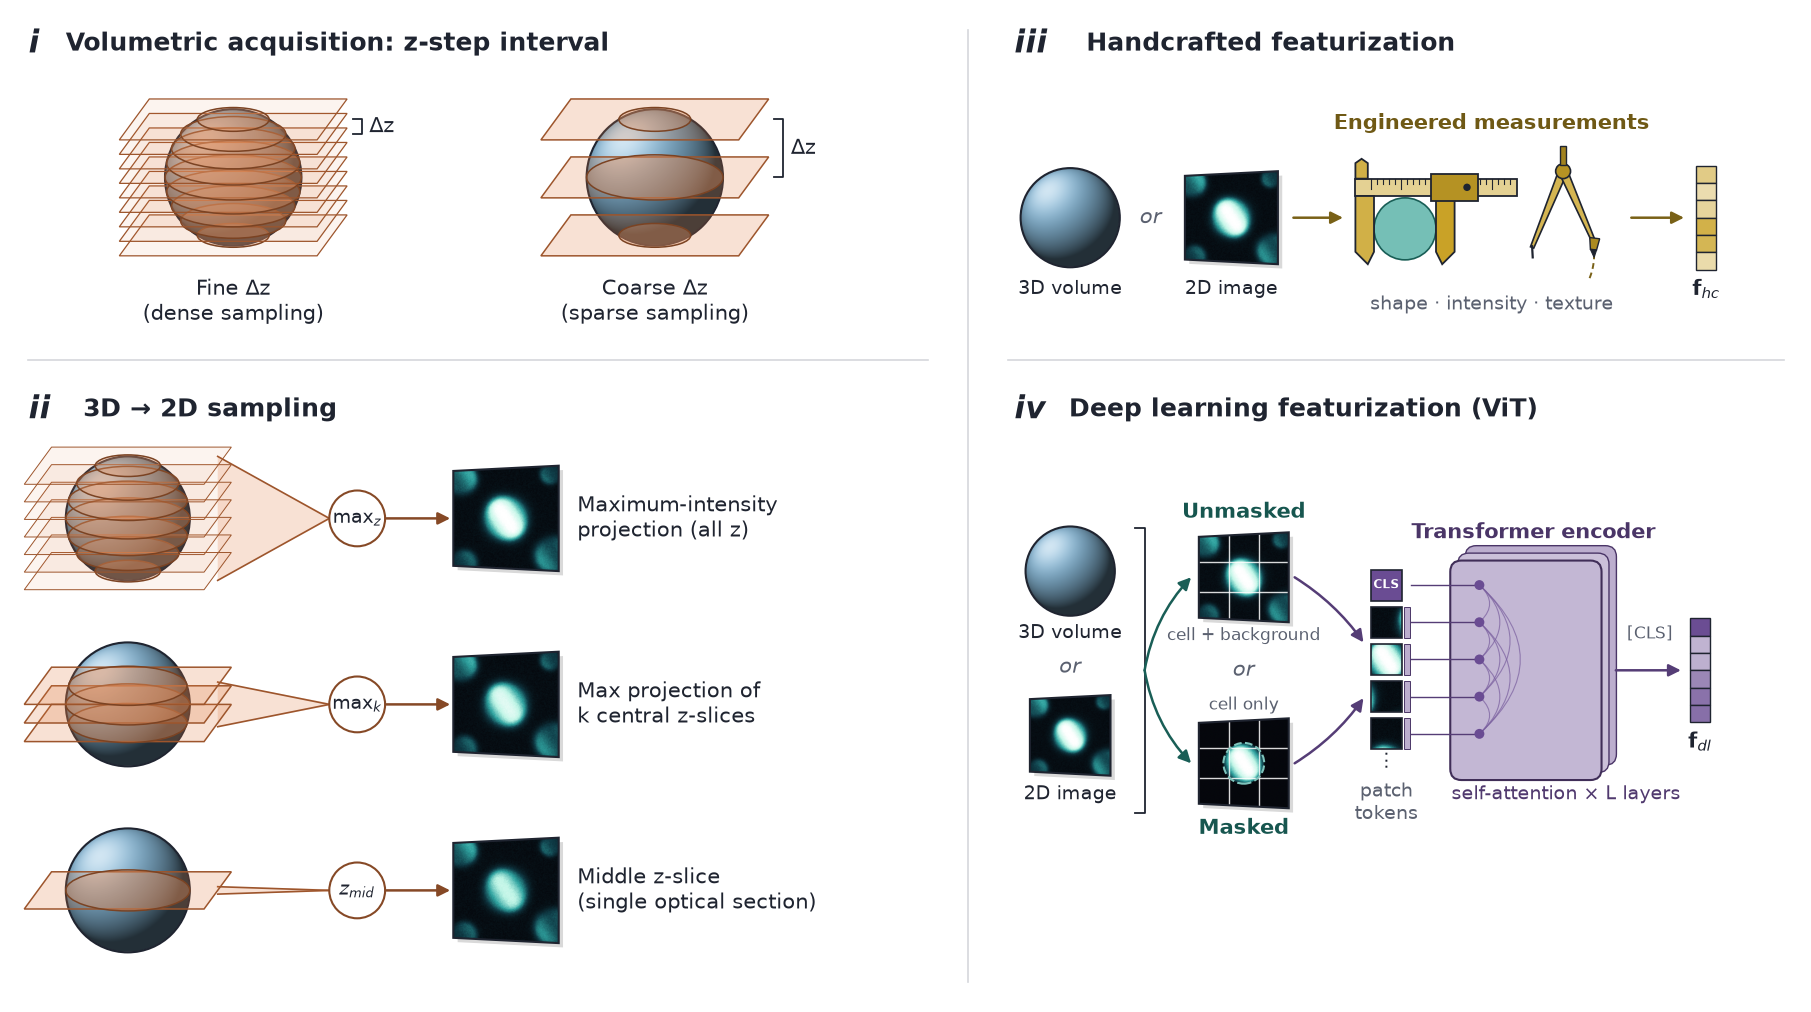

In [9]:
def make_figure(save_prefix="featurization_overview", unit_in=0.62):
    """2 x 2 layout. Left column: acquisition (i) over 3D->2D sampling (ii).
    Right column: handcrafted (iii) over deep learning (iv). Every panel is drawn at the same scale."""
    LW, RW, CG = 15.0, 13.0, 0.9  # left/right column widths, column gap (drawing units)
    R1, R2, RG = 5.4, 10.1, 0.5  # top/bottom row heights, row gap
    W, H = LW + CG + RW, R2 + RG + R1
    fig = plt.figure(figsize=(W * unit_in, H * unit_in))

    def panel_ax(x0, y0, w, ylim):
        a = fig.add_axes([x0 / W, y0 / H, w / W, (ylim[1] - ylim[0]) / H])
        a.set_xlim(0, w)
        a.set_ylim(*ylim)
        a.set_aspect("equal")
        a.axis("off")
        return a

    top = R2 + RG
    panel_acquisition(panel_ax(0, top, LW, (24.3, 29.7)), y=27.0)
    panel_sampling(panel_ax(0, 0, LW, (13.7, 23.8)), y_top=21.5)
    panel_handcrafted(panel_ax(LW + CG, top, RW, (8.85, 14.25)), y=10.9, title_dy=2.8)
    panel_deep(panel_ax(LW + CG, 0, RW, (-0.65, 9.45)), y=4.8, title_dy=4.1)
    separator(fig, (LW + CG / 2) / W, 0.02, (LW + CG / 2) / W, 0.98)  # column divider
    separator(
        fig, 0.01, (R2 + RG / 2) / H, (LW - 0.2) / W, (R2 + RG / 2) / H
    )  # row divider, left
    separator(
        fig, (LW + CG + 0.2) / W, (R2 + RG / 2) / H, 0.99, (R2 + RG / 2) / H
    )  # row divider, right
    if save_prefix:
        fig.savefig(
            f"{output_figure_file_path}",
            dpi=600,
            bbox_inches="tight",
            facecolor="white",
        )
    return fig


fig = make_figure()
plt.show()